**Step 0**

Research Question:

How many wildfire-smoke days did St. Cloud, Minnesota have each summer from 2023 to 2026, and what weather conditions came with them?

Project Slice:
Location: St. Cloud, Minnesota
Study period: Summers of 2023–2026
Months: June 1 through September 30
Air quality measurement: PM2.5 (µg/m³)
Weather measurements: Rainfall, temperature, wind speed, and wind direction.
Main smoke-day threshold: Daily mean PM2.5 of 35.5 µg/m³ or higher.
Moderate pollution threshold: Daily mean PM2.5 above 9 µg/m³.


Data Sources:

Source 1: Open-Meteo Air Quality API

Website: https://open-meteo.com/en/docs/air-quality-api

This source provides hourly air-quality measurements, including:

PM2.5: Fine particulate matter concentration.
US AQI: United States Air Quality Index.
US AQI PM2.5: Air quality index calculated from PM2.5.
Aerosol optical depth: A measurement that can help identify atmospheric haze.

Source 2: Open-Meteo Historical Weather API

Website: https://open-meteo.com/en/docs/historical-weather-api

This source provides daily weather measurements, including:

Total daily precipitation (inches).
Maximum daily temperature (°F).
Maximum wind speed (mph).
Dominant wind direction (degrees).

I will also use the Open-Meteo Geocoding API to verify the correct St. Cloud location and coordinates before downloading the data.

Geocoding API: https://open-meteo.com/en/docs/geocoding-api

Extract → Transform → Load → Analyze Plan:

Extract: Download air-quality and weather data from Open-Meteo for each summer from 2023 through 2026.

Transform: Clean missing values, convert hourly air-quality measurements into daily averages, and combine the air-quality data with daily weather data.

Load: Save the cleaned datasets as CSV files and store them in a SQLite database.

Analyze: Count smoke days, identify the worst air-quality days, examine consecutive smoke episodes, and compare weather conditions on smoky and normal days.

Data Pipeline Diagram

EXTRACT
Open-Meteo Air Quality API + Historical Weather API
↓
TRANSFORM
Clean data, calculate daily PM2.5 averages, and combine weather data
↓
LOAD
Save clean CSV files and SQLite database
↓
ANALYZE
Count smoke days, identify worst days, compare wind and rainfall, and create charts.

**Step 1**

1.1
imports reqests, pandas, matplotlib.pyplot, sqlite3, json, datetime, and os libraries. requests is used to connect to API's. Pandas is used to put data into tables, matplotlib is used to make charts and graphs, sqlite3 is used to save data into SQL database, json is used to read and save data from API's, and datetime is used to convert dates and times to new formats. The os library is used to access the filesystem in colab.

1.2
Defines parameters for city, state, country, latitude, and longitude so the API's know from where to retrieve the data from.

1.3
Defines parameters for the time period I am studying. 2023-2026 data is being used.

1.4
Defines a moderately smokey day as less than 9.0 milligrams a meter cubed and a smokey day as anything up until 35.5 milligrams a meter cubed.

1.5
Creates 3 data folders with os.makedirs() command. Folders for raw data, clean data, and the finished graphs are created.

1.6
Displays the folders created and the parameters that were defined to confirm everything is running correctly.

In [ ]:

# ==========================================
# STEP 1: SETUP
# ==========================================

# SECTION 1: INSTALL AND IMPORT LIBRARIES

!pip install -q requests pandas matplotlib

import requests
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import json
import datetime
import os

print("All libraries imported successfully!")


# SECTION 2: SET THE PROJECT LOCATION

# These are the approximate coordinates for St. Cloud, Minnesota.
# We will verify the correct location using the Geocoding API in Step 2.

city = "St. Cloud"
state = "Minnesota"
country = "United States"

latitude = 45.5579
longitude = -94.1632

print("\nPROJECT LOCATION")
print("City:", city)
print("State:", state)
print("Country:", country)
print("Latitude:", latitude)
print("Longitude:", longitude)


# SECTION 3: SET THE STUDY PERIOD

# The project examines four summers, from 2023 through 2026.
# Each summer runs from June 1 through September 30.

study_years = [2023, 2024, 2025, 2026]

start_month_day = "06-01"
end_month_day = "09-30"

print("\nSTUDY PERIOD")
print("Years:", study_years)
print("Start date: June 1")
print("End date: September 30")


# SECTION 4: SET AIR QUALITY THRESHOLDS

# PM2.5 measures fine particles in the air.
# Higher values indicate more particle pollution.
#
# Above 9.0 µg/m³ = Moderate pollution day
# At least 35.5 µg/m³ = Main smoke-day threshold

moderate_threshold = 9.0
smoke_threshold = 35.5

# A day must have at least 18 valid hourly readings
# out of 24 to be included in the daily analysis.

minimum_valid_hours = 18

print("\nAIR QUALITY SETTINGS")
print("Moderate threshold:", moderate_threshold, "µg/m³")
print("Smoke-day threshold:", smoke_threshold, "µg/m³")
print("Minimum valid hourly readings:", minimum_valid_hours)


# SECTION 5: CREATE PROJECT FOLDERS

# data/raw: Stores the original API responses.
# data/clean: Stores cleaned datasets and CSV files.
# charts: Stores finished charts and graphs.

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)
os.makedirs("charts", exist_ok=True)

print("\nPROJECT FOLDERS CREATED")
print("data/raw/")
print("data/clean/")
print("charts/")


# SECTION 6: CONFIRM SETUP

print("\n==========================================")
print("STEP 1 COMPLETED SUCCESSFULLY!")
print("==========================================")

print("Location:", city, state)
print("Study years:", study_years)
print("Smoke threshold:", smoke_threshold, "µg/m³")
print("All project folders are ready.")


All libraries imported successfully!

PROJECT LOCATION
City: St. Cloud
State: Minnesota
Country: United States
Latitude: 45.5579
Longitude: -94.1632

STUDY PERIOD
Years: [2023, 2024, 2025, 2026]
Start date: June 1
End date: September 30

AIR QUALITY SETTINGS
Moderate threshold: 9.0 µg/m³
Smoke-day threshold: 35.5 µg/m³
Minimum valid hourly readings: 18

PROJECT FOLDERS CREATED
data/raw/
data/clean/
charts/

STEP 1 COMPLETED SUCCESSFULLY!
Location: St. Cloud Minnesota
Study years: [2023, 2024, 2025, 2026]
Smoke threshold: 35.5 µg/m³
All project folders are ready.


1.1
libraries are imported.

1.2
parameters for location are defined.

1.3
parameters for date are defined.

1.4
smokey and moderately smokey days are defined.

1.5
3 folders are created.

1.6
paramters and folders are displayed.

**Step 2**

2.1
Gives google colab the URL's to the API's that we will be using.

2.2
Requests.get() to look for st.cloud with the previously defined geo_params. The code then saves the data to the raw data folder. This step then makes sure colab selects the right St.Cloud in Minnesota and prints the result.

2.3
Set the study years and store data into the air quality data and weather data.

2.4
Retrieves air quality data with requests.get() and with air_params. Saves the results into the air quality folder inside the raw data folder as a json file. Counts the number of records retrieved and prints.

2.5
Retrieves weather data with requests.get() and weather_params. saves the results inside the weather folder inside the raw data folder as a json file. counts the number of records retrieved and prints.

2.6
Prints a final extraction summary by counting the records retrieved and says where the data was saved.

In [ ]:

# ==========================================
# STEP 2: EXTRACT DATA FROM THE APIS
# ==========================================

# SECTION 1: SET UP API URLS

# These are the three Open-Meteo APIs we will use.

geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"

air_quality_url = "https://air-quality-api.open-meteo.com/v1/air-quality"

weather_url = "https://archive-api.open-meteo.com/v1/archive"


# SECTION 2: GEOCODING API
# Find the correct St. Cloud, Minnesota.

try:

    geo_params = {
        "name": "St. Cloud",
        "count": 10,
        "language": "en",
        "format": "json"
    }

    geo_response = requests.get(
        geocoding_url,
        params=geo_params,
        timeout=60
    )


    # Save the original response unchanged.
    with open("data/raw/geocoding.json", "w") as file:
        file.write(geo_response.text)

    geo_data = geo_response.json()
    geo_results = geo_data.get("results", [])


    # Select matching St. Cloud locations in Minnesota, USA.
    matches = [
        place for place in geo_results
        if "st. cloud" in place.get("name", "").casefold()
        and place.get("admin1", "").casefold() == "minnesota"
        and place.get("country", "").casefold() == "united states"
    ]

    if not matches:
        raise ValueError(
            "Could not find the exact St. Cloud, Minnesota result."
        )

    # Use the first matching result.
    selected_location = matches[0]

    latitude = selected_location["latitude"]
    longitude = selected_location["longitude"]

    print("\nSELECTED LOCATION")
    print("City:", selected_location["name"])
    print("State:", selected_location["admin1"])
    print("Country:", selected_location["country"])
    print("Latitude:", latitude)
    print("Longitude:", longitude)

except Exception as e:
    raise RuntimeError(f"Geocoding request failed: {e}")


# SECTION 3: SET UP THE FOUR STUDY SUMMERS

# We will request one summer at a time.
# This follows the project instructions.

study_years = [2023, 2024, 2025, 2026]

# Store downloaded responses for later exploration.
air_quality_data = {}
weather_data = {}


# SECTION 4: DOWNLOAD AIR QUALITY DATA

# Hourly variables:
# PM2.5, US AQI, US AQI for PM2.5,
# and aerosol optical depth.

air_variables = (
    "pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth"
)

for year in study_years:

    try:

        start_date = f"{year}-06-01"
        end_date = f"{year}-09-30"

        air_params = {
            "latitude": latitude,
            "longitude": longitude,
            "hourly": air_variables,
            "start_date": start_date,
            "end_date": end_date,
            "timezone": "America/Chicago"
        }

        air_response = requests.get(
            air_quality_url,
            params=air_params,
            timeout=120
        )

        print(
            f"\nAir quality {year} status:",
            air_response.status_code
        )

        # Stop if the API reports an error.
        air_response.raise_for_status()

        # Save original JSON response unchanged.
        filename = f"data/raw/air_quality_{year}.json"

        with open(filename, "w") as file:
            file.write(air_response.text)

        # Read the JSON response.
        air_json = air_response.json()

        air_quality_data[year] = air_json

        # Count hourly records using the time list.
        hourly_records = len(
            air_json.get("hourly", {}).get("time", [])
        )

        print("Year:", year)
        print("Air quality hourly records:", hourly_records)
        print("Saved:", filename)

    except Exception as e:
        raise RuntimeError(
            f"Air quality download failed for {year}: {e}"
        )


# SECTION 5: DOWNLOAD HISTORICAL WEATHER DATA

# Daily variables:
# Total precipitation, maximum temperature,
# maximum wind speed, and dominant wind direction.

weather_variables = (
    "precipitation_sum,temperature_2m_max,"
    "wind_speed_10m_max,wind_direction_10m_dominant"
)

for year in study_years:

    try:

        start_date = f"{year}-06-01"
        end_date = f"{year}-09-30"

        weather_params = {
            "latitude": latitude,
            "longitude": longitude,
            "start_date": start_date,
            "end_date": end_date,
            "daily": weather_variables,
            "timezone": "America/Chicago",
            "precipitation_unit": "inch",
            "temperature_unit": "fahrenheit",
            "wind_speed_unit": "mph"
        }

        weather_response = requests.get(
            weather_url,
            params=weather_params,
            timeout=120
        )

        print(
            f"\nWeather {year} status:",
            weather_response.status_code
        )

        weather_response.raise_for_status()

        # Save the original JSON response unchanged.
        filename = f"data/raw/weather_{year}.json"

        with open(filename, "w") as file:
            file.write(weather_response.text)

        # Read the JSON response.
        weather_json = weather_response.json()

        weather_data[year] = weather_json

        # Count daily records.
        daily_records = len(
            weather_json.get("daily", {}).get("time", [])
        )

        print("Year:", year)
        print("Weather daily records:", daily_records)
        print("Saved:", filename)

    except Exception as e:
        raise RuntimeError(
            f"Weather download failed for {year}: {e}"
        )


# SECTION 6: FINAL EXTRACTION SUMMARY

print("\n==========================================")
print("STEP 2 COMPLETED SUCCESSFULLY!")
print("==========================================")

print("\nStudy years:", study_years)

print("\nAIR QUALITY RECORD COUNTS")

for year in study_years:
    count = len(air_quality_data[year]["hourly"]["time"])
    print(year, ":", count, "hourly records")

print("\nWEATHER RECORD COUNTS")

for year in study_years:
    count = len(weather_data[year]["daily"]["time"])
    print(year, ":", count, "daily records")

print("\nRAW FILES SAVED IN data/raw/")
print("1. geocoding.json")

for year in study_years:
    print(f"2. air_quality_{year}.json")
    print(f"3. weather_{year}.json")

print("\nAll API requests completed!")


SELECTED LOCATION
City: St. Cloud Regional Airport
State: Minnesota
Country: United States
Latitude: 45.54639
Longitude: -94.05972

Air quality 2023 status: 200
Year: 2023
Air quality hourly records: 2928
Saved: data/raw/air_quality_2023.json

Air quality 2024 status: 200
Year: 2024
Air quality hourly records: 2928
Saved: data/raw/air_quality_2024.json

Air quality 2025 status: 200
Year: 2025
Air quality hourly records: 2928
Saved: data/raw/air_quality_2025.json

Air quality 2026 status: 200
Year: 2026
Air quality hourly records: 2928
Saved: data/raw/air_quality_2026.json

Weather 2023 status: 200
Year: 2023
Weather daily records: 122
Saved: data/raw/weather_2023.json

Weather 2024 status: 200
Year: 2024
Weather daily records: 122
Saved: data/raw/weather_2024.json

Weather 2025 status: 200
Year: 2025
Weather daily records: 122
Saved: data/raw/weather_2025.json

Weather 2026 status: 200
Year: 2026
Weather daily records: 122
Saved: data/raw/weather_2026.json

STEP 2 COMPLETED SUCCESSFUL

2.1 Gives google colab the URL's to the API's that we will be using.

2.2
The St.Cloud in MN is chosen. There seems to be only data from the regional airport, which is fine since its still in st.cloud.

2.3
the study years are set.

2.4
air quality data is retrieved.

2.5
weather data is retrieved.

2.6
number of records from each API is printed.

**Step 3**

3.1
JSON files are loaded from the raw data folder for the study years using with open.

3.2
Converts the data into a data frame with pd.dataframe. Add the data tables by year to air_frames and weather_frames. combines all summers into 2 tables using the pd.concat command and converts the date/time into the correct format using pd.to_datetime.

3.3
prints the rows and columns in the data set and tables.

3.4
Counts the number of missing values in the dataset with the isnull().sum() command and prints the number of missing rows/columns.

3.5
Counts the number of hours that have valid measurements using .count(). Then finds the number of missing hours by doing 24-missing_values and prints the number of days that have less than 24 valid hours and the number of days with less than 18 valid hours with .sum().

3.6
Counts the number of duplicate data in weather_df and air_df using the .duplicated() and .sum commands.

3.7
Prints the number of missing values, incomplete hourly readings, duplicated records, and checks if there are any unexpected hours in the data by using the len() code.

In [ ]:

# ==========================================
# STEP 3: EXPLORE THE RAW DATA
# ==========================================


# SECTION 1: LOAD THE ORIGINAL JSON FILES
# Read the original API responses saved in Step 2.
# We are not cleaning or changing the data yet.

study_years = [2023, 2024, 2025, 2026]

air_quality_data = {}
weather_data = {}

for year in study_years:

    # Load air-quality JSON
    air_file = f"data/raw/air_quality_{year}.json"

    with open(air_file, "r") as file:
        air_quality_data[year] = json.load(file)

    # Load weather JSON
    weather_file = f"data/raw/weather_{year}.json"

    with open(weather_file, "r") as file:
        weather_data[year] = json.load(file)

print("Original JSON files loaded successfully!")


# SECTION 2: CONVERT JSON DATA INTO DATAFRAMES
# Convert hourly air-quality information into tables.
# Convert daily weather information into separate tables.
# Add a year column so we can identify each summer.

air_frames = []
weather_frames = []

for year in study_years:

    hourly = air_quality_data[year]["hourly"]
    daily = weather_data[year]["daily"]


    # Create air-quality DataFrame
    air_year_df = pd.DataFrame(hourly)
    air_year_df["year"] = year

    air_frames.append(air_year_df)

    # Create weather DataFrame
    weather_year_df = pd.DataFrame(daily)
    weather_year_df["year"] = year

    weather_frames.append(weather_year_df)


# Combine all four summers into two datasets.
air_df = pd.concat(air_frames, ignore_index=True)
weather_df = pd.concat(weather_frames, ignore_index=True)

# Convert date and time columns into datetime format.
air_df["time"] = pd.to_datetime(air_df["time"])
weather_df["time"] = pd.to_datetime(weather_df["time"])

print("\nDATAFRAMES CREATED SUCCESSFULLY!")


# SECTION 3: DISPLAY DATASET INFORMATION
# Show the number of rows, columns, and data types.
# This helps us understand the size and structure of the data.

print("\nAIR QUALITY DATA OVERVIEW")

print("Rows:", air_df.shape[0])
print("Columns:", air_df.shape[1])

print("\nColumn names:")
print(list(air_df.columns))

print("\nData types:")
print(air_df.dtypes)

print("\nFirst 5 rows:")
display(air_df.head())


print("\nWEATHER DATA OVERVIEW")

print("Rows:", weather_df.shape[0])
print("Columns:", weather_df.shape[1])

print("\nColumn names:")
print(list(weather_df.columns))

print("\nData types:")
print(weather_df.dtypes)

print("\nFirst 5 rows:")
display(weather_df.head())


# SECTION 4: CHECK MISSING VALUES
# Count missing values in each column.
# Missing values can affect daily averages and analysis.

print("\nAIR QUALITY MISSING VALUES")

air_missing = air_df.isnull().sum()
display(air_missing.to_frame("Missing values"))

print("\nWEATHER MISSING VALUES")

weather_missing = weather_df.isnull().sum()
display(weather_missing.to_frame("Missing values"))


# SECTION 5: CHECK MISSING HOURLY READINGS BY DAY
# Count the number of valid PM2.5 readings for each day.
# A complete day should normally have 24 hourly readings.
# We will later require at least 18 valid readings.

air_df["date"] = air_df["time"].dt.date

daily_valid_hours = air_df.groupby("date")["pm2_5"].count()

daily_missing_hours = 24 - daily_valid_hours

print("\nMISSING HOURLY READINGS")

print("Days with fewer than 24 valid PM2.5 readings:",
      (daily_valid_hours < 24).sum())

print("Days with fewer than 18 valid PM2.5 readings:",
      (daily_valid_hours < 18).sum())

print("\nDays with missing hourly readings:")

display(
    daily_valid_hours[
        daily_valid_hours < 24
    ].to_frame("Valid PM2.5 hours")
)


# SECTION 6: CHECK DUPLICATES
# Duplicate timestamps or dates could cause problems
# when combining air-quality and weather datasets.

air_duplicates = air_df["time"].duplicated().sum()

weather_duplicates = weather_df["time"].duplicated().sum()

print("\nDUPLICATE CHECK")

print("Duplicate air-quality timestamps:", air_duplicates)

print("Duplicate weather dates:", weather_duplicates)


# SECTION 7: IDENTIFY DATA-QUALITY PROBLEMS
# Print the results of our quality checks.
# These are potential problems to investigate in Step 4.

print("\n==========================================")
print("DATA QUALITY CHECK")
print("==========================================")

# Problem 1: Missing values
print("\n1. MISSING VALUES")

if air_missing.sum() > 0 or weather_missing.sum() > 0:
    print("Missing measurements were found.")
else:
    print("No missing measurements were found.")

# Problem 2: Incomplete hourly readings
print("\n2. INCOMPLETE HOURLY READINGS")

incomplete_days = (daily_valid_hours < 24).sum()

print("Days with incomplete PM2.5 readings:", incomplete_days)

# Problem 3: Duplicate records
print("\n3. DUPLICATE RECORDS")

print("Air-quality duplicates:", air_duplicates)
print("Weather duplicates:", weather_duplicates)


# Problem 4: Unexpected record counts
print("\n4. EXPECTED RECORD COUNTS")

expected_hours = 122 * 24
expected_days = 122

for year in study_years:

    actual_hours = len(
        air_quality_data[year]["hourly"]["time"]
    )

    actual_days = len(
        weather_data[year]["daily"]["time"]
    )

    print(
        year,
        "| Air quality:", actual_hours,
        "| Weather:", actual_days
    )

    if actual_hours != expected_hours:
        print("  Air-quality record count differs from expected.")

    if actual_days != expected_days:
        print("  Weather record count differs from expected.")


Original JSON files loaded successfully!

DATAFRAMES CREATED SUCCESSFULLY!

AIR QUALITY DATA OVERVIEW
Rows: 11712
Columns: 6

Column names:
['time', 'pm2_5', 'us_aqi', 'us_aqi_pm2_5', 'aerosol_optical_depth', 'year']

Data types:
time                     datetime64[ns]
pm2_5                           float64
us_aqi                            int64
us_aqi_pm2_5                      int64
aerosol_optical_depth           float64
year                              int64
dtype: object

First 5 rows:


,time,pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth,year
0,2023-06-01 00:00:00,12.0,66,58,0.30,2023
1,2023-06-01 01:00:00,12.5,62,58,0.31,2023
2,2023-06-01 02:00:00,13.1,58,58,0.30,2023
3,2023-06-01 03:00:00,13.5,58,58,0.31,2023
4,2023-06-01 04:00:00,13.6,58,58,0.30,2023



WEATHER DATA OVERVIEW
Rows: 488
Columns: 6

Column names:
['time', 'precipitation_sum', 'temperature_2m_max', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'year']

Data types:
time                           datetime64[ns]
precipitation_sum                     float64
temperature_2m_max                    float64
wind_speed_10m_max                    float64
wind_direction_10m_dominant             int64
year                                    int64
dtype: object

First 5 rows:


,time,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant,year
0,2023-06-01,0.004,90.5,15.5,148,2023
1,2023-06-02,0.815,85.5,11.3,134,2023
2,2023-06-03,0.374,85.6,8.2,85,2023
3,2023-06-04,0.000,91.0,7.1,79,2023
4,2023-06-05,0.008,87.0,8.4,64,2023



AIR QUALITY MISSING VALUES


,Missing values
time,0
pm2_5,0
us_aqi,0
us_aqi_pm2_5,0
aerosol_optical_depth,0
year,0



WEATHER MISSING VALUES


,Missing values
time,0
precipitation_sum,0
temperature_2m_max,0
wind_speed_10m_max,0
wind_direction_10m_dominant,0
year,0



MISSING HOURLY READINGS
Days with fewer than 24 valid PM2.5 readings: 0
Days with fewer than 18 valid PM2.5 readings: 0

Days with missing hourly readings:


,Valid PM2.5 hours
date,



DUPLICATE CHECK
Duplicate air-quality timestamps: 0
Duplicate weather dates: 0

DATA QUALITY CHECK

1. MISSING VALUES
No missing measurements were found.

2. INCOMPLETE HOURLY READINGS
Days with incomplete PM2.5 readings: 0

3. DUPLICATE RECORDS
Air-quality duplicates: 0
Weather duplicates: 0

4. EXPECTED RECORD COUNTS
2023 | Air quality: 2928 | Weather: 122
2024 | Air quality: 2928 | Weather: 122
2025 | Air quality: 2928 | Weather: 122
2026 | Air quality: 2928 | Weather: 122


3.1 JSON files are loaded from the raw data folder.

3.2
Data converted to panda data frame and date is converted to correct format.

3.3
Rows/columns counted.

3.4
Number of missing values counted.

3.5
Number of days with invalid measurements counted.

3.6
duplicate data counted.

3.7
The results from steps 3.4-3.6 printed as well as the number of unexpected hours printed.

**Step 4**

4.1
Copies of air and weather data made. The rows before cleaning are counted with len() and printed.

4.2
Weather and air quality measurements are converted to numeric values with pd.to_numeric and date/time are converted to timestamps with pd.to_datetime.

4.3
.drop_duplicates is used to drop duplicated data.

4.4
Uses .dropna to drop the rows containing missing data points. Then converts the cleaned data into the date and time format with .dt.date.

4.5
Drops unreasonable values such as negative air concentrations with  invalid = air_clean[column] < 0, and similarily drops negative weather values with invalid = weather_clean[column] < 0 and replaces them with na values with np.nan.

4.6
Identifies the 1st and 3 quartiles with quantile() code and then finds interquartile range (iqr) by subtracting q1 from q3. Then sets lower limits and upper limits for the data that is used by q1-1.5*iqr and q3+1.5*iqr respectively. Then uses the defined check_outliers function to find outliers in each of the datasets.

4.7
Prints the lengths of the new cleaned data sets using len().

In [ ]:

# ==========================================
# STEP 4: CLEAN AND TRANSFORM THE DATA
# ==========================================

import numpy as np

# SECTION 1: MAKE COPIES OF THE ORIGINAL DATA
# We create copies so that the original DataFrames
# from Step 3 are not accidentally changed.

air_clean = air_df.copy()
weather_clean = weather_df.copy()

# Record the original row counts.
air_rows_before = len(air_clean)
weather_rows_before = len(weather_clean)

print("ORIGINAL ROW COUNTS")
print("Air quality:", air_rows_before)
print("Weather:", weather_rows_before)


# SECTION 2: FIX WRONG DATA TYPES
# Convert measurement columns into numeric values.
# Any values that cannot be converted become NaN.
# Convert timestamps into proper datetime formats.

air_numeric_columns = [
    "pm2_5",
    "us_aqi",
    "us_aqi_pm2_5",
    "aerosol_optical_depth"
]

weather_numeric_columns = [
    "precipitation_sum",
    "temperature_2m_max",
    "wind_speed_10m_max",
    "wind_direction_10m_dominant"
]

# Convert air-quality measurements.
for column in air_numeric_columns:
    air_clean[column] = pd.to_numeric(
        air_clean[column],
        errors="coerce"
    )

# Convert weather measurements.
for column in weather_numeric_columns:
    weather_clean[column] = pd.to_numeric(
        weather_clean[column],
        errors="coerce"
    )

# Convert timestamps.
air_clean["time"] = pd.to_datetime(
    air_clean["time"],
    errors="coerce"
)

weather_clean["time"] = pd.to_datetime(
    weather_clean["time"],
    errors="coerce"
)

print("\nSECTION 2: DATA TYPES FIXED")
print("Air quality types:")
print(air_clean.dtypes)

print("\nWeather types:")
print(weather_clean.dtypes)


# SECTION 3: REMOVE DUPLICATE RECORDS
# Duplicate timestamps could cause the same hour
# or day to be counted more than once.
# We keep the first occurrence of each timestamp.

air_clean = air_clean.drop_duplicates(
    subset=["time"],
    keep="first"
).copy()

weather_clean = weather_clean.drop_duplicates(
    subset=["time"],
    keep="first"
).copy()

print("\nSECTION 3: DUPLICATES REMOVED")
print("Air-quality duplicates removed:", air_duplicates)
print("Weather duplicates removed:", weather_duplicates)


# SECTION 4: HANDLE MISSING VALUES
# Rows without a valid date or timestamp cannot be
# reliably assigned to a particular hour or day.
# We remove those rows.
#
# We do NOT replace missing PM2.5 with zero.
# Zero would incorrectly suggest that there was
# no particle pollution.
#
# We keep other missing measurements as NaN.

air_missing_timestamps = air_clean["time"].isna().sum()
weather_missing_timestamps = weather_clean["time"].isna().sum()

air_clean = air_clean.dropna(subset=["time"]).copy()
weather_clean = weather_clean.dropna(subset=["time"]).copy()

# Re-create the date column from the cleaned timestamp.
air_clean["date"] = air_clean["time"].dt.date
weather_clean["date"] = weather_clean["time"].dt.date

print("\nSECTION 4: MISSING VALUES")
print("Invalid air timestamps removed:",
      air_missing_timestamps)

print("Invalid weather timestamps removed:",
      weather_missing_timestamps)

print("\nRemaining air-quality missing values:")
print(air_clean[air_numeric_columns].isna().sum())

print("\nRemaining weather missing values:")
print(weather_clean[weather_numeric_columns].isna().sum())


# SECTION 5: FIX INVALID MEASUREMENTS
# Some measurements should not have negative values.
# We replace physically invalid values with NaN.
#
# This prevents impossible measurements from
# affecting our calculations.

# Air-quality measurements cannot be negative.
for column in air_numeric_columns:
    invalid = air_clean[column] < 0
    air_clean.loc[invalid, column] = np.nan

# Weather measurements that cannot be negative.
nonnegative_weather_columns = [
    "precipitation_sum",
    "wind_speed_10m_max"
]

for column in nonnegative_weather_columns:
    invalid = weather_clean[column] < 0
    weather_clean.loc[invalid, column] = np.nan



print("\nSECTION 5: INVALID MEASUREMENTS FIXED")
print("Negative pollution, rainfall and wind-speed values")
print("were changed to missing values.")



# SECTION 6: IDENTIFY POSSIBLE OUTLIERS
# Outliers are unusually high or low measurements.
# We use the IQR method to identify unusual values.
#
# We DO NOT automatically delete them.
# High PM2.5 values may represent genuine smoke events.
# Removing them could damage our analysis.

def check_outliers(data, column):

    values = data[column].dropna()

    if len(values) == 0:
        return 0

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = (
        (values < lower_limit) |
        (values > upper_limit)
    )

    return outliers.sum()


print("\nSECTION 6: POSSIBLE OUTLIERS")

for column in [
    "pm2_5",
    "us_aqi",
    "temperature_2m_max",
    "precipitation_sum",
    "wind_speed_10m_max"
]:

    if column in air_clean.columns:
        count = check_outliers(air_clean, column)

    elif column in weather_clean.columns:
        count = check_outliers(weather_clean, column)

    else:
        continue

    print(column, ":", count, "possible outliers")

print("\nPossible outliers are flagged for review,")
print("not automatically deleted.")


# SECTION 7: CHECK THE NUMBER OF VALID PM2.5 HOURS
# We need enough hourly readings to calculate
# a reliable daily PM2.5 average.
#
# Our project rule requires at least 18 valid
# hourly PM2.5 readings out of 24.
#
# We calculate the valid hours for every day.
# Daily aggregation will happen in Step 5.

daily_valid_hours = (
    air_clean.groupby("date")["pm2_5"]
    .count()
)

valid_days = daily_valid_hours[
    daily_valid_hours >= 18
]

unusable_days = daily_valid_hours[
    daily_valid_hours < 18
]

print("\nSECTION 7: DAILY PM2.5 DATA QUALITY")

print("Days with at least 18 valid readings:",
      len(valid_days))

print("Days with fewer than 18 valid readings:",
      len(unusable_days))


# SECTION 8: FINAL ROW COUNT COMPARISON
# Compare the number of rows before and after cleaning.
# This shows whether our cleaning procedures
# removed any records.

air_rows_after = len(air_clean)
weather_rows_after = len(weather_clean)

print("\n==========================================")
print("ROW COUNT COMPARISON")
print("==========================================")

print("\nAIR QUALITY")
print("Before cleaning:", air_rows_before)
print("After cleaning:", air_rows_after)
print("Rows removed:", air_rows_before - air_rows_after)

print("\nWEATHER")
print("Before cleaning:", weather_rows_before)
print("After cleaning:", weather_rows_after)
print("Rows removed:", weather_rows_before - weather_rows_after)


# SECTION 9: DISPLAY THE CLEANED DATA
# Display the first five rows of each cleaned dataset.
# We will use these DataFrames in Step 5.

print("\nCLEANED AIR QUALITY DATA")
display(air_clean.head())

print("\nCLEANED WEATHER DATA")
display(weather_clean.head())

print("\n==========================================")
print("STEP 4 COMPLETED SUCCESSFULLY!")
print("==========================================")

print("Cleaned air-quality rows:", len(air_clean))
print("Cleaned weather rows:", len(weather_clean))

print("Data is ready for Step 5: Combine and Derive.")

ORIGINAL ROW COUNTS
Air quality: 11712
Weather: 488

SECTION 2: DATA TYPES FIXED
Air quality types:
time                     datetime64[ns]
pm2_5                           float64
us_aqi                            int64
us_aqi_pm2_5                      int64
aerosol_optical_depth           float64
year                              int64
date                             object
dtype: object

Weather types:
time                           datetime64[ns]
precipitation_sum                     float64
temperature_2m_max                    float64
wind_speed_10m_max                    float64
wind_direction_10m_dominant             int64
year                                    int64
dtype: object

SECTION 3: DUPLICATES REMOVED
Air-quality duplicates removed: 0
Weather duplicates removed: 0

SECTION 4: MISSING VALUES
Invalid air timestamps removed: 0
Invalid weather timestamps removed: 0

Remaining air-quality missing values:
pm2_5                    0
us_aqi                   0
us_aqi_pm2_5 

,time,pm2_5,us_aqi,us_aqi_pm2_5,aerosol_optical_depth,year,date
0,2023-06-01 00:00:00,12.0,66.0,58.0,0.30,2023,2023-06-01
1,2023-06-01 01:00:00,12.5,62.0,58.0,0.31,2023,2023-06-01
2,2023-06-01 02:00:00,13.1,58.0,58.0,0.30,2023,2023-06-01
3,2023-06-01 03:00:00,13.5,58.0,58.0,0.31,2023,2023-06-01
4,2023-06-01 04:00:00,13.6,58.0,58.0,0.30,2023,2023-06-01



CLEANED WEATHER DATA


,time,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant,year,date
0,2023-06-01,0.004,90.5,15.5,148,2023,2023-06-01
1,2023-06-02,0.815,85.5,11.3,134,2023,2023-06-02
2,2023-06-03,0.374,85.6,8.2,85,2023,2023-06-03
3,2023-06-04,0.000,91.0,7.1,79,2023,2023-06-04
4,2023-06-05,0.008,87.0,8.4,64,2023,2023-06-05



STEP 4 COMPLETED SUCCESSFULLY!
Cleaned air-quality rows: 11712
Cleaned weather rows: 488
Data is ready for Step 5: Combine and Derive.


4.1
Copies of air and weather data made.

4.2
Weather and air quality measurements are converted to numeric values and timestamps made.

4.3
duplicated data dropped.

4.4
data with missing portions dropped.

4.5
unreasonable data dropped.

4.6
Outliers in the data flagged.

4.7
Counts of cleaned data shown.

**Step 5**

5.1
Puts Air and weather data into a shared date column based off of time with .dt.date code.

5.2
Aggregates the average air quality per hour with .agg code. Groups the data by date with .groupby() code.

5.3
Defines what a moderate and smokey day are based off of it being greater or less than the threshold of milligrams a meter cubed. Adds all the days in each category with .sum() code.

5.4
Uses pd.merge to merge the air quality and weather data into one table.

5.5
Defines what a northerly wind is and what a rainy day is. Northern winds come from 315 degrees to 45 degrees, and rainy days have precipitation greater than 0.

5.6
The combined data is converted to a date with the pd.to_datetime, and then converted to year with .dt.year to create a year column in the table.

5.7 Prints the final data set and uses len() to count missing values and columns.

5.8
Makes a summary for the total amount of moderate, smokey, and usable days with the .agg() code. Then displays the summary with display().

5.9
Prints the row counts.


In [ ]:

# ==========================================
# STEP 5: COMBINE AND DERIVE
# ==========================================

# SECTION 1: PREPARE THE SHARED DATE COLUMN
# Air quality is hourly, while weather is daily.
# We use the date (not the hour) as our shared key.

air_clean["date"] = pd.to_datetime(
    air_clean["time"]
).dt.date

weather_clean["date"] = pd.to_datetime(
    weather_clean["time"]
).dt.date

# SECTION 2: AGGREGATE HOURLY AIR QUALITY INTO DAILY DATA
# Group all hourly readings by date.
#
# Daily mean PM2.5: Average particle pollution.
# Daily maximum AQI: Highest AQI recorded that day.
# Daily mean aerosol optical depth: Average haze indicator.
# Valid hours: Number of available PM2.5 readings.

air_daily = (
    air_clean.groupby("date")
    .agg(
        daily_mean_pm25=("pm2_5", "mean"),
        daily_max_aqi=("us_aqi", "max"),
        daily_max_aqi_pm25=("us_aqi_pm2_5", "max"),
        daily_mean_aod=("aerosol_optical_depth", "mean"),
        valid_pm25_hours=("pm2_5", "count")
    )
    .reset_index()
)

# A day is usable if it has at least 18 valid hours.
air_daily["usable_day"] = air_daily["valid_pm25_hours"] >= 18

print("\nDAILY AIR QUALITY CREATED")
print("Number of daily records:", len(air_daily))
display(air_daily.head())


# SECTION 3: CREATE POLLUTION AND SMOKE FLAGS
# Moderate pollution: Daily mean PM2.5 above 9.
# Smoke day: Daily mean PM2.5 at or above 35.5.
#
# Days without enough valid readings are not counted
# as either moderate or smoke days.

air_daily["moderate_day"] = (
    air_daily["usable_day"] &
    (air_daily["daily_mean_pm25"] > 9.0)
)

air_daily["smoke_day"] = (
    air_daily["usable_day"] &
    (air_daily["daily_mean_pm25"] >= 35.5)
)

print("\nSMOKE FLAGS CREATED")
print("Moderate pollution days:",
      air_daily["moderate_day"].sum())

print("Smoke days:",
      air_daily["smoke_day"].sum())


# SECTION 4: JOIN THE TWO DATASETS
# Use an OUTER JOIN so we can identify every date
# appearing in either dataset.
#
# The date column is the shared key.
# The indicator tells us whether each date matched.

combined_df = pd.merge(
    air_daily,
    weather_clean,
    on="date",
    how="outer",
    indicator=True
)

print("\nDATASETS COMBINED")
print("Total combined rows:", len(combined_df))

print("\nJOIN RESULTS")
print(combined_df["_merge"].value_counts())


# SECTION 5: CREATE ADDITIONAL WEATHER COLUMNS
# Add a wind category to help compare wind directions.
#
# Northerly winds come from the northwest through northeast.
# Their direction is approximately 315 to 45 degrees.
#
# Rainy days are days with measurable precipitation.

combined_df["northerly_wind"] = (
    (combined_df["wind_direction_10m_dominant"] >= 315) |
    (combined_df["wind_direction_10m_dominant"] <= 45)
)

combined_df["rainy_day"] = (
    combined_df["precipitation_sum"] > 0
)

# Missing wind directions and rainfall should not
# be interpreted as known wind or rain conditions.
combined_df.loc[
    combined_df["wind_direction_10m_dominant"].isna(),
    "northerly_wind"
] = pd.NA

combined_df.loc[
    combined_df["precipitation_sum"].isna(),
    "rainy_day"
] = pd.NA


# SECTION 6: ADD YEAR AND SEASON INFORMATION
# Create a year column for comparing the four summers.

combined_df["date"] = pd.to_datetime(
    combined_df["date"]
)

combined_df["year"] = combined_df["date"].dt.year

combined_df["season"] = (
    combined_df["year"].astype(str) + " Summer"
)

# Keep the matched dates as our main analysis dataset.
matched_dates = combined_df[combined_df["_merge"] == "both"].copy()
analysis_df = matched_dates.copy()

analysis_df["date"] = pd.to_datetime(
    analysis_df["date"]
)

analysis_df["year"] = analysis_df["date"].dt.year

analysis_df["season"] = (
    analysis_df["year"].astype(str) + " Summer"
)


# SECTION 7: FINAL DATA CHECK
# Display the final combined dataset.
# Check the columns and missing values.

print("\nFINAL ANALYSIS DATA")
print("Rows:", len(analysis_df))
print("Columns:", len(analysis_df.columns))

print("\nColumn names:")
print(list(analysis_df.columns))

print("\nMissing values:")
print(analysis_df.isna().sum())

print("\nFirst 10 rows:")
display(analysis_df.head(10))


# SECTION 8: SMOKE DAY SUMMARY BY YEAR
# Count valid smoke days and moderate pollution days
# for each summer.

yearly_summary = (
    analysis_df.groupby("year")
    .agg(
        smoke_days=("smoke_day", "sum"),
        moderate_days=("moderate_day", "sum"),
        usable_days=("usable_day", "sum")
    )
    .reset_index()
)

print("\nYEARLY SMOKE DAY SUMMARY")
display(yearly_summary)


# SECTION 9: FINAL ROW COUNTS AND CONFIRMATION

print("\n==========================================")
print("STEP 5 COMPLETED SUCCESSFULLY!")
print("==========================================")

print("Daily air-quality records:", len(air_daily))
print("Daily weather records:", len(weather_clean))
print("Combined records:", len(combined_df))
print("Matched analysis records:", len(analysis_df))

print("\nYour main analysis dataset is: analysis_df")
print("Your full joined dataset is: combined_df")
print("Your yearly smoke summary is: yearly_summary")

print("\nReady for Step 6: Load into SQLite and CSV!")


DAILY AIR QUALITY CREATED
Number of daily records: 488


,date,daily_mean_pm25,daily_max_aqi,daily_max_aqi_pm25,daily_mean_aod,valid_pm25_hours,usable_day
0,2023-06-01,13.008333,103.0,58.0,0.300000,24,True
1,2023-06-02,17.391667,98.0,66.0,0.402917,24,True
2,2023-06-03,16.600000,119.0,66.0,0.371667,24,True
3,2023-06-04,15.945833,92.0,65.0,0.353750,24,True
4,2023-06-05,21.045833,76.0,72.0,0.438750,24,True



SMOKE FLAGS CREATED
Moderate pollution days: 221
Smoke days: 4

DATASETS COMBINED
Total combined rows: 488

JOIN RESULTS
_merge
both          488
left_only       0
right_only      0
Name: count, dtype: int64

FINAL ANALYSIS DATA
Rows: 488
Columns: 19

Column names:
['date', 'daily_mean_pm25', 'daily_max_aqi', 'daily_max_aqi_pm25', 'daily_mean_aod', 'valid_pm25_hours', 'usable_day', 'moderate_day', 'smoke_day', 'time', 'precipitation_sum', 'temperature_2m_max', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'year', '_merge', 'northerly_wind', 'rainy_day', 'season']

Missing values:
date                           0
daily_mean_pm25                0
daily_max_aqi                  0
daily_max_aqi_pm25             0
daily_mean_aod                 0
valid_pm25_hours               0
usable_day                     0
moderate_day                   0
smoke_day                      0
time                           0
precipitation_sum              0
temperature_2m_max             0
wind_spee

/tmp/ipykernel_593/1503326449.py:112: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  combined_df.loc[
/tmp/ipykernel_593/1503326449.py:117: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  combined_df.loc[


,date,daily_mean_pm25,daily_max_aqi,daily_max_aqi_pm25,daily_mean_aod,valid_pm25_hours,usable_day,moderate_day,smoke_day,time,precipitation_sum,temperature_2m_max,wind_speed_10m_max,wind_direction_10m_dominant,year,_merge,northerly_wind,rainy_day,season
0,2023-06-01,13.008333,103.0,58.0,0.300000,24,True,True,False,2023-06-01,0.004,90.5,15.5,148,2023,both,False,True,2023 Summer
1,2023-06-02,17.391667,98.0,66.0,0.402917,24,True,True,False,2023-06-02,0.815,85.5,11.3,134,2023,both,False,True,2023 Summer
2,2023-06-03,16.600000,119.0,66.0,0.371667,24,True,True,False,2023-06-03,0.374,85.6,8.2,85,2023,both,False,True,2023 Summer
3,2023-06-04,15.945833,92.0,65.0,0.353750,24,True,True,False,2023-06-04,0.000,91.0,7.1,79,2023,both,False,False,2023 Summer
4,2023-06-05,21.045833,76.0,72.0,0.438750,24,True,True,False,2023-06-05,0.008,87.0,8.4,64,2023,both,False,True,2023 Summer
5,2023-06-06,19.650000,75.0,75.0,0.523750,24,True,True,False,2023-06-06,0.071,87.6,11.4,75,2023,both,False,True,2023 Summer
6,2023-06-07,19.187500,70.0,70.0,0.482083,24,True,True,False,2023-06-07,0.909,81.2,10.6,84,2023,both,False,True,2023 Summer
7,2023-06-08,18.000000,73.0,71.0,0.311667,24,True,True,False,2023-06-08,0.000,80.3,9.1,109,2023,both,False,False,2023 Summer
8,2023-06-09,17.158333,69.0,69.0,0.375833,24,True,True,False,2023-06-09,0.000,82.4,7.2,178,2023,both,False,False,2023 Summer
9,2023-06-10,15.841667,67.0,67.0,0.449167,24,True,True,False,2023-06-10,0.217,78.3,15.8,39,2023,both,True,True,2023 Summer



YEARLY SMOKE DAY SUMMARY


,year,smoke_days,moderate_days,usable_days
0,2023,2,85,122
1,2024,0,64,122
2,2025,2,44,122
3,2026,0,28,122



STEP 5 COMPLETED SUCCESSFULLY!
Daily air-quality records: 488
Daily weather records: 488
Combined records: 488
Matched analysis records: 488

Your main analysis dataset is: analysis_df
Your full joined dataset is: combined_df
Your yearly smoke summary is: yearly_summary

Ready for Step 6: Load into SQLite and CSV!


5.1
Air and weather data in same data table based off of time..

5.2
air quality summed up for each day.

5.3
moderate and smokey days are defined.

5.4
air quality and weather data merged into one table.

5.5
Northerly wind and rainy days are defined.

5.6
year column created.

5.7
Rows with missing values are counted.

5.8
Summary for moderate, usable, and smokey days is displayed.

5.9
Printed the row counts.

**Step 6**

6.1
Four datasets saved in tables. Air quality data, weather data, combined data, analysis data saved using tables={} code.

6.2
Uses dataframe.to_csv to convert the dataframes from part 1 into csv files so SQLite can read it.

6.3
SQLite connection established with sqlite3.connect with connection name "data/clean/smoke_season.db".

6.4
Converts datetimes from pandas into text with is_datetime64_any_dtype. Converts boolean values into 0's and 1's with pd.BooleanDtype. Converts data columns into text with pd.CategoricalDtype.

6.5
transfers data sets to SQLite with sql_df.to_sql.

6.6
Asks for smoke days by year from SQLite by defining query1 and using pd.read_sql_query code.

6.7
Asks for worst smoke days from SQLite by defining query2 and using pd.read_sql_query.

6.8
Closes the connection to SQLite with connection.close().

In [ ]:

# ==========================================
# STEP 6: LOAD DATA INTO CSV AND SQLITE
# ==========================================


# SECTION 1: PREPARE THE DATASETS
# We will save four datasets:
#
# air_daily: Daily air-quality measurements.
# weather_clean: Daily weather measurements.
# combined_df: All joined dates, including unmatched dates.
# analysis_df: Matched dates used for the analysis.

tables = {
    "air_quality": air_daily,
    "weather": weather_clean,
    "combined_data": combined_df,
    "analysis_data": analysis_df
}

print("\nDATASETS PREPARED")

for name, dataframe in tables.items():
    print(name, ":", len(dataframe), "rows")


# SECTION 2: SAVE DATASETS AS CSV FILES
# CSV files can be opened in Excel, Google Sheets,
# and Python.
#
# Each dataset gets its own CSV file.

for name, dataframe in tables.items():

    filename = f"data/clean/{name}.csv"

    dataframe.to_csv(
        filename,
        index=False
    )

    print("Saved:", filename)


# SECTION 3: CREATE THE SQLITE DATABASE
# SQLite allows us to store tables and retrieve
# information using SQL queries.
#
# The database will be saved in data/clean/.

database_path = "data/clean/smoke_season.db"

connection = sqlite3.connect(database_path)

print("\nSQLite database created:")
print(database_path)


# SECTION 4: PREPARE DATA FOR SQLITE
# Convert dates and special pandas data types into
# formats SQLite can store.
#
# Boolean values become 1 or 0.
# Missing Boolean values remain NULL.
# Dates become text strings.

def prepare_for_sql(dataframe):

    sql_df = dataframe.copy()

    for column in sql_df.columns:

        # Convert datetime values into text.
        if pd.api.types.is_datetime64_any_dtype(
            sql_df[column]
        ):
            sql_df[column] = sql_df[column].astype(str)

        # Convert Boolean values into 1 and 0.
        elif isinstance(
            sql_df[column].dtype,
            pd.BooleanDtype
        ) or pd.api.types.is_bool_dtype(
            sql_df[column]
        ):
            sql_df[column] = sql_df[column].map(
                lambda value:
                None if pd.isna(value) else int(value)
            )

        # Convert category columns into text.
        elif isinstance(
            sql_df[column].dtype,
            pd.CategoricalDtype
        ):
            sql_df[column] = sql_df[column].astype(str)

    return sql_df


# SECTION 5: SAVE DATASETS AS SQLITE TABLES
# Each DataFrame becomes a separate table.
# if_exists="replace" updates an existing table
# if the code is run again.

for name, dataframe in tables.items():

    sql_df = prepare_for_sql(dataframe)

    sql_df.to_sql(
        name,
        connection,
        if_exists="replace",
        index=False
    )

    print(
        "SQLite table created:",
        name,
        "| Rows:",
        len(sql_df)
    )



# SECTION 6: SQL QUERY 1 - COUNT SMOKE DAYS BY YEAR
# This query counts the number of smoke days
# in each summer.
#
# It also shows the number of moderate pollution days.
# Only usable days are counted.

print("\n==========================================")
print("SQL QUERY 1: SMOKE DAYS BY YEAR")
print("==========================================")

query1 = """
SELECT
    year,
    SUM(CASE WHEN smoke_day = 1 THEN 1 ELSE 0 END)
        AS smoke_days,
    SUM(CASE WHEN moderate_day = 1 THEN 1 ELSE 0 END)
        AS moderate_days,
    SUM(CASE WHEN usable_day = 1 THEN 1 ELSE 0 END)
        AS usable_days
FROM analysis_data
GROUP BY year
ORDER BY year;
"""

result1 = pd.read_sql_query(
    query1,
    connection
)

display(result1)


# SECTION 7: SQL QUERY 2 - FIND THE WORST AIR QUALITY DAYS
# This query identifies the days with the highest
# daily mean PM2.5 concentrations.
#
# These results will help us identify the worst
# pollution days in our analysis.

print("\n==========================================")
print("SQL QUERY 2: WORST PM2.5 DAYS")
print("==========================================")

query2 = """
SELECT
    date,
    year,
    daily_mean_pm25,
    daily_max_aqi,
    precipitation_sum,
    wind_speed_10m_max
FROM analysis_data
WHERE usable_day = 1
ORDER BY daily_mean_pm25 DESC
LIMIT 10;
"""

result2 = pd.read_sql_query(
    query2,
    connection
)

display(result2)


# SECTION 8: CLOSE DATABASE CONNECTION
# Closing the connection makes sure that
# the database is no longer being accessed.

connection.close()

print("\n==========================================")
print("STEP 6 COMPLETED SUCCESSFULLY!")
print("==========================================")

print("CSV files saved in data/clean/")
print("SQLite database saved in data/clean/")
print("Your data is ready for Step 7!")



DATASETS PREPARED
air_quality : 488 rows
weather : 488 rows
combined_data : 488 rows
analysis_data : 488 rows
Saved: data/clean/air_quality.csv
Saved: data/clean/weather.csv
Saved: data/clean/combined_data.csv
Saved: data/clean/analysis_data.csv

SQLite database created:
data/clean/smoke_season.db
SQLite table created: air_quality | Rows: 488
SQLite table created: weather | Rows: 488
SQLite table created: combined_data | Rows: 488
SQLite table created: analysis_data | Rows: 488

SQL QUERY 1: SMOKE DAYS BY YEAR


,year,smoke_days,moderate_days,usable_days
0,2023,2,85,122
1,2024,0,64,122
2,2025,2,44,122
3,2026,0,28,122



SQL QUERY 2: WORST PM2.5 DAYS


,date,year,daily_mean_pm25,daily_max_aqi,precipitation_sum,wind_speed_10m_max
0,2023-06-14,2023,53.500000,142.0,0.000,7.2
1,2023-07-23,2023,43.954167,118.0,0.000,6.3
2,2025-08-01,2025,40.700000,112.0,0.000,4.9
3,2025-07-31,2025,35.979167,100.0,0.000,5.1
4,2025-06-01,2025,35.433333,105.0,0.000,9.3
5,2025-08-11,2025,33.070833,95.0,0.000,11.6
6,2023-07-15,2023,32.387500,127.0,0.000,15.0
7,2023-06-28,2023,30.912500,93.0,0.622,12.6
8,2023-07-24,2023,30.745833,140.0,0.118,12.8
9,2023-06-17,2023,30.025000,93.0,0.008,13.9



STEP 6 COMPLETED SUCCESSFULLY!
CSV files saved in data/clean/
SQLite database saved in data/clean/
Your data is ready for Step 7!


6.1 Four datasets saved in tables.

6.2 data frames converted to CSV files.

6.3 SQLite connection established.

6.4 Datetimes converted into text. Boolean values converted to just 0's and 1's and null values. Data columns converted into text.

6.5 data sets transferred to SQLite.

6.6 Asks for smoke days by year.

6.7 Asks for worst smoke days.

6.8 Closes the connection to SQLite.

**Step 7**

7.1
Creates a chart with plt.plot() with daily mean pm levels. Adds titles and labels, and a horizontal threshold line with plt.axhline that signifies the smoke threshold for a smokey day.

7.2
Makes a chart for smoke days per year. Uses groupby("year") to group the sum() of the flagged days by year. Makes a barchart with plt.bar to show the number of smokey days per summer every year.

7.3
Makes a function for compass degrees with def to track what direction the wind is coming from. Uses pd.crosstab to display smoke days along with the wind direction.

7.4
Aggregates the average maximum wind speed and daily precipitation with the .agg() code grouped by smoke_days with groupby() code. Uses .plot() to make a doublebar plot of smoke days and non-smoke days precipitation and wind speed.

7.5
Makes a pandas summary dataframe grouped by year with summary().groupby() code and then aggregates data with .agg(). Makes a table showing the total smoke days, highest/average pm25, average wind speed, and average precipitation by year.

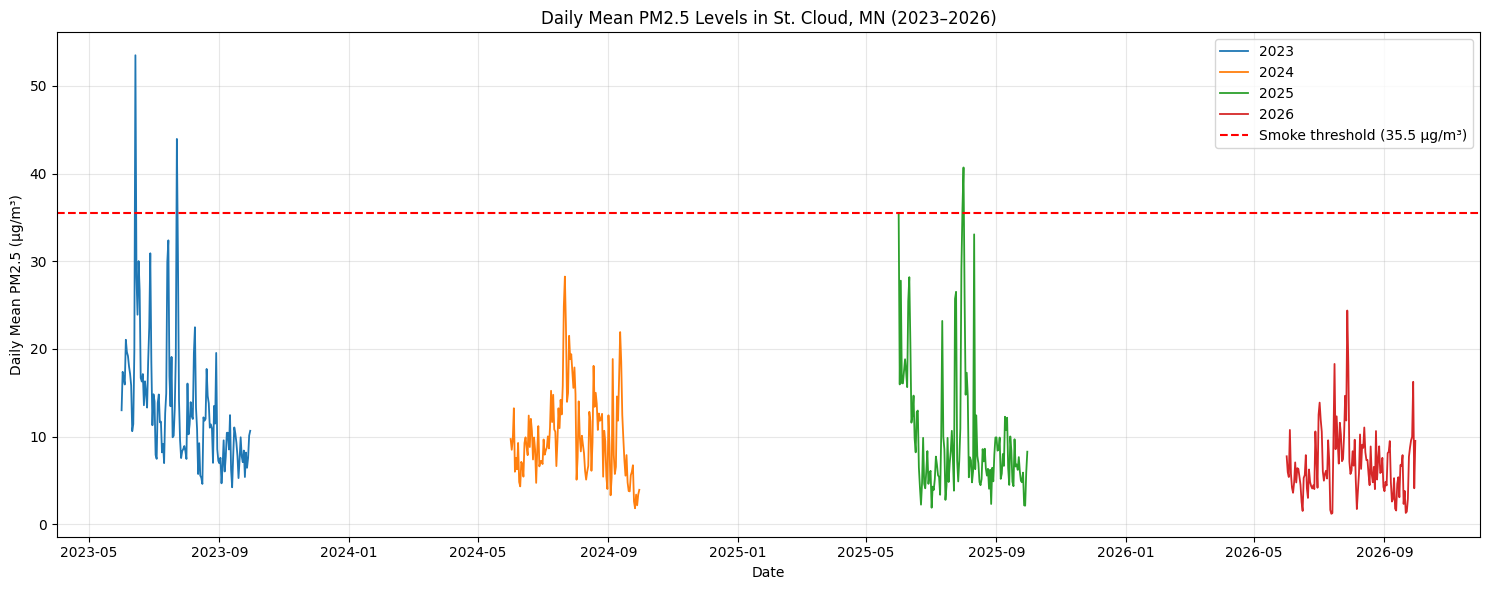


CHART 1 INTERPRETATION:
This chart shows daily changes in PM2.5 concentrations in
St. Cloud during the summers of 2023–2026. Days above the
red line meet the project's smoke-day definition. The highest
peaks represent the days with the greatest PM2.5 pollution.



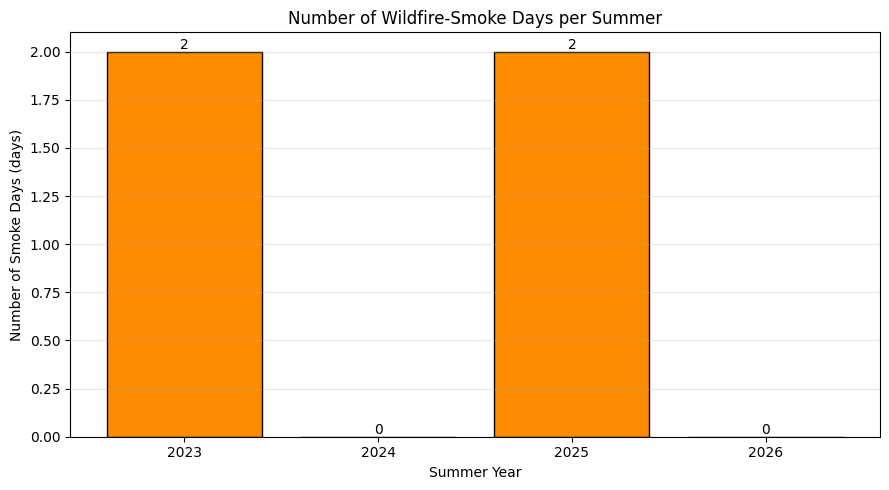


CHART 2 INTERPRETATION:
This chart compares the number of smoke days during each
summer. The tallest bar represents the summer with the most
days when daily mean PM2.5 reached at least 35.5 µg/m³.



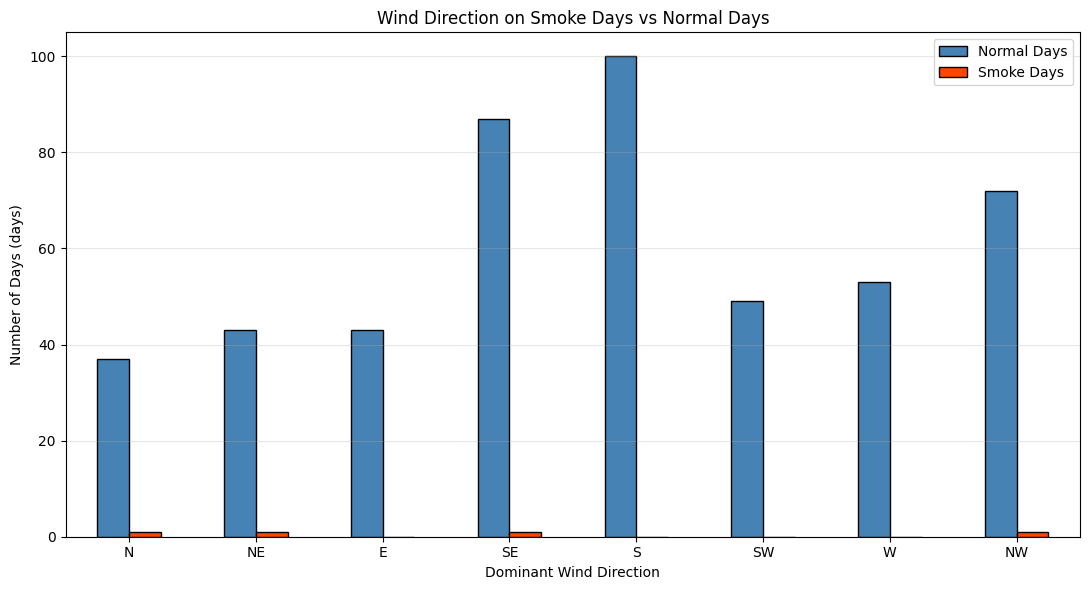


CHART 3 INTERPRETATION:
This chart compares wind directions on smoke days and normal
days. If smoke days occur more frequently with northerly or
northwesterly winds, this may suggest smoke transport from
areas to the north or northwest. Wind direction alone cannot
identify the actual source of the wildfire smoke.



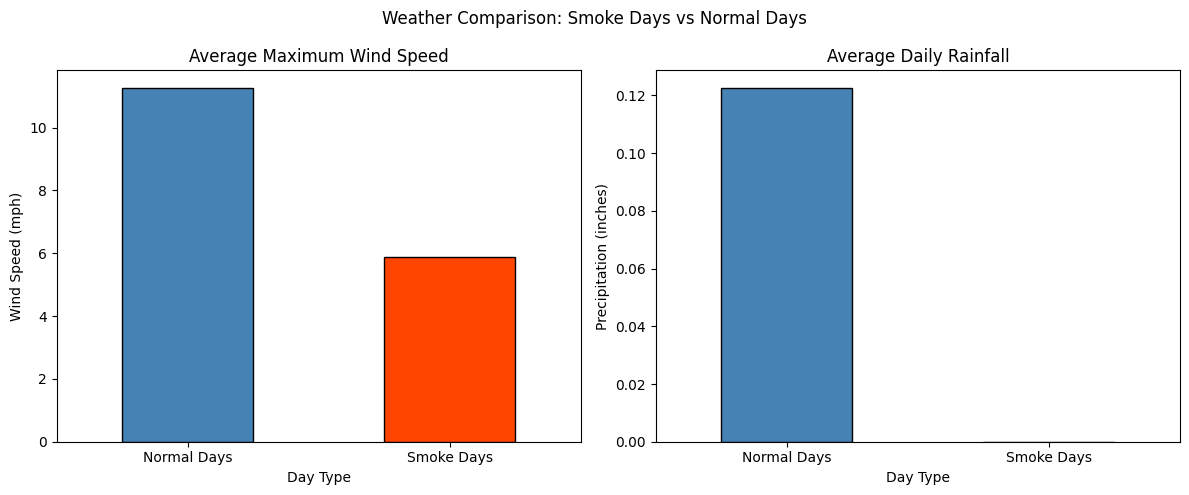


CHART 4 INTERPRETATION:
These charts compare average maximum wind speed and rainfall
on smoke days versus normal days. They help identify whether
smoke days tend to have stronger winds or less rainfall.
The comparisons show associations, not proof of cause and effect.


FINAL SUMMER SUMMARY
      smoke_days  moderate_smoke_days  highest_pm25  average_pm25  average_wind_speed  average_rainfall
year                                                                                                   
2023           2                   85         53.50         13.49               11.33              0.12
2024           0                   64         28.25         10.10               11.52              0.15
2025           2                   44         40.70         10.09               10.85              0.12
2026           0                   28         24.38          6.85               11.18              0.09


In [ ]:

# ===========================================================
# STEP 7: ANALYZE AND VISUALIZE WILDFIRE SMOKE IN ST. CLOUD, MN
# ===========================================================


# ------------------------------------------------------------
# SECTION 1: CHART 1 - DAILY PM2.5 LEVELS
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

for year in range(2023, 2027):
    summer = analysis_df[analysis_df["year"] == year]

    plt.plot(
        summer["date"],
        summer["daily_mean_pm25"],
        label=str(year),
        linewidth=1.3
    )

plt.axhline(
    y=smoke_threshold,
    color="red",
    linestyle="--",
    label="Smoke threshold (35.5 µg/m³)"
)

plt.title("Daily Mean PM2.5 Levels in St. Cloud, MN (2023–2026)")
plt.xlabel("Date")
plt.ylabel("Daily Mean PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("charts/daily_pm25_levels.png", dpi=300)
plt.show()

print("""
CHART 1 INTERPRETATION:
This chart shows daily changes in PM2.5 concentrations in
St. Cloud during the summers of 2023–2026. Days above the
red line meet the project's smoke-day definition. The highest
peaks represent the days with the greatest PM2.5 pollution.
""")


# ------------------------------------------------------------
# SECTION 2: CHART 2 - SMOKE DAYS PER SUMMER
# ------------------------------------------------------------

smoke_counts = (
    analysis_df.groupby("year")["smoke_day"]
    .sum()
    .reindex(range(2023, 2027), fill_value=0)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    smoke_counts.index.astype(str),
    smoke_counts.values,
    color="darkorange",
    edgecolor="black"
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.title("Number of Wildfire-Smoke Days per Summer")
plt.xlabel("Summer Year")
plt.ylabel("Number of Smoke Days (days)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("charts/smoke_days_per_summer.png", dpi=300)
plt.show()

print("""
CHART 2 INTERPRETATION:
This chart compares the number of smoke days during each
summer. The tallest bar represents the summer with the most
days when daily mean PM2.5 reached at least 35.5 µg/m³.
""")


# ------------------------------------------------------------
# SECTION 3: CHART 3 - WIND DIRECTION
# ------------------------------------------------------------

def compass_direction(degrees):
    if pd.isna(degrees):
        return np.nan

    directions = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    index = int((degrees + 22.5) // 45) % 8
    return directions[index]

analysis_df["wind_compass"] = analysis_df["wind_direction_10m_dominant"].apply(compass_direction)

wind_data = pd.crosstab(
    analysis_df["wind_compass"],
    analysis_df["smoke_day"]
)

wind_data = wind_data.reindex(
    ["N", "NE", "E", "SE", "S", "SW", "W", "NW"],
    fill_value=0
)

# Safely verify and name comparison columns
if len(wind_data.columns) == 2:
    wind_data.columns = ["Normal Days", "Smoke Days"]
elif len(wind_data.columns) == 1:
    # If no smoke days are present in subset or logic defaults
    wind_data.columns = ["Normal Days"]

wind_data.plot(
    kind="bar",
    figsize=(11, 6),
    color=["steelblue", "orangered"][:len(wind_data.columns)],
    edgecolor="black"
)

plt.title("Wind Direction on Smoke Days vs Normal Days")
plt.xlabel("Dominant Wind Direction")
plt.ylabel("Number of Days (days)")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("charts/wind_direction_comparison.png", dpi=300)
plt.show()

print("""
CHART 3 INTERPRETATION:
This chart compares wind directions on smoke days and normal
days. If smoke days occur more frequently with northerly or
northwesterly winds, this may suggest smoke transport from
areas to the north or northwest. Wind direction alone cannot
identify the actual source of the wildfire smoke.
""")


# ------------------------------------------------------------
# SECTION 4: CHART 4 - WIND SPEED AND RAINFALL
# ------------------------------------------------------------

weather_comparison = analysis_df.groupby("smoke_day").agg(
    average_wind_speed=("wind_speed_10m_max", "mean"),
    average_rainfall=("precipitation_sum", "mean")
)

weather_comparison = weather_comparison.reindex([False, True])
weather_comparison.index = ["Normal Days", "Smoke Days"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

weather_comparison["average_wind_speed"].plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "orangered"],
    edgecolor="black"
)

axes[0].set_title("Average Maximum Wind Speed")
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Wind Speed (mph)")
axes[0].tick_params(axis="x", rotation=0)

weather_comparison["average_rainfall"].plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "orangered"],
    edgecolor="black"
)

axes[1].set_title("Average Daily Rainfall")
axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("Precipitation (inches)")
axes[1].tick_params(axis="x", rotation=0)

plt.suptitle("Weather Comparison: Smoke Days vs Normal Days")
plt.tight_layout()
plt.savefig("charts/weather_comparison.png", dpi=300)
plt.show()

print("""
CHART 4 INTERPRETATION:
These charts compare average maximum wind speed and rainfall
on smoke days versus normal days. They help identify whether
smoke days tend to have stronger winds or less rainfall.
The comparisons show associations, not proof of cause and effect.
""")



# ------------------------------------------------------------
# SECTION 5: FINAL SUMMARY TABLE
# ------------------------------------------------------------

summary = analysis_df.groupby("year").agg(
    smoke_days=("smoke_day", "sum"),
    moderate_smoke_days=("moderate_day", "sum"),
    highest_pm25=("daily_mean_pm25", "max"),
    average_pm25=("daily_mean_pm25", "mean"),
    average_wind_speed=("wind_speed_10m_max", "mean"),
    average_rainfall=("precipitation_sum", "mean")
)

summary = summary.reindex(range(2023, 2027))

print("\n" + "=" * 60)
print("FINAL SUMMER SUMMARY")
print("=" * 60)
print(summary.round(2).to_string())


**Step 8**

From Chart 2, we can see that 2023 and 2025 both received 2 wildfire smoke day when daily mean PM2.5 reached 35.5 milligrams a meter cubed. 2024 and 2026 both received 0 in their summers. Graph 1 shows us that 2024 and 2026 both had similar PM2.5, both sitting well below the threshold for a wildfire smoke day, whereas 2023 and 2025's smoke days seemed to be very isolated incidents and were trending back to the levels that 2024 and 2026 had. This might be explained by chart 4, which tells us that there was almost no rain on smoke days when compared to normal days. Max wind speed was also usually about 5 mph lower than normal days as well. From chart 3, there doesn't really seem to be any common factor in the direction of the wind with the smoke days.

Some limitations of this data include us not involving all the factors that dictate when a smoke day occurs. Wind, precipitation, and direction may not be the only things that affect air quality. There also is only 4 wildfire smoke days since 2023, so there is a lack of data to draw conclusions from for this project to be considered fact.


Open-Meteo air quality API provided the air quality data for this project, Open-Meteo Geocoding API transferred St.Cloud into coordinates, and Open-Meteo Historical Weather API has provided the weather data. ChatGPT has written the code for this project as well.